# Chapter 13: Hypothesis Tests

Companion notebook for *Master Exploratory Data Analysis: A Hands-On Beginner's Guide with Python, Statistics & A/B Testing*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files are in the same folder as this notebook.

## 13.1 What a Test Asks

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.style.use('book.mplstyle')

orders = pd.read_csv('orders.csv', parse_dates=['order_date'])
customers = pd.read_csv('customers.csv', parse_dates=['signup_date'])
survey = pd.read_csv('survey.csv', parse_dates=['response_date'])
cancellations = pd.read_csv('cancellations.csv',
                            parse_dates=['cancel_date'])

delivery = orders['delivery_days']
print(f'{len(delivery):,} orders, average {delivery.mean():.2f} days')

28,772 orders, average 3.30 days


### Simulating a world with no gap

In [2]:
rng = np.random.default_rng(42)
on_promise = delivery - delivery.mean() + 3

sim_means = []
for _ in range(1000):
    fake = rng.choice(on_promise, size=len(delivery))
    sim_means.append(fake.mean())
sim_means = np.array(sim_means)
print(f'Lowest: {sim_means.min():.2f}  Highest: {sim_means.max():.2f}')

Lowest: 2.97  Highest: 3.03


In [3]:
real_gap = delivery.mean() - 3
far_out = np.abs(sim_means - 3) >= abs(real_gap)
print(f'Fake samples with a gap this big: {far_out.sum()} of 1,000')

Fake samples with a gap this big: 0 of 1,000


### Shuffling labels

In [4]:
responses = survey.merge(customers, on='customer_id',
                         validate='one_to_one')
(responses.groupby('device')['satisfaction']
    .agg(['mean', 'count'])
    .round(3))

,mean,count
device,,
Desktop,3.660,194
Mobile,3.618,338


In [5]:
satisfaction = responses['satisfaction'].to_numpy()
is_mobile = (responses['device'] == 'Mobile').to_numpy()
real_gap = (satisfaction[is_mobile].mean()
            - satisfaction[~is_mobile].mean())

shuffled_gaps = []
for _ in range(10_000):
    labels = rng.permutation(is_mobile)
    shuffled_gaps.append(satisfaction[labels].mean()
                         - satisfaction[~labels].mean())
shuffled_gaps = np.array(shuffled_gaps)
print(f'Real gap (mobile minus desktop): {real_gap:.3f}')

Real gap (mobile minus desktop): -0.041


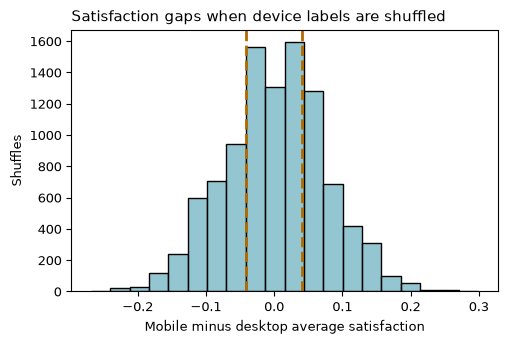

In [6]:
fig, ax = plt.subplots()
sns.histplot(shuffled_gaps, bins=20, color='#6fb3c2', ax=ax)
ax.axvline(real_gap, color='#b26a00', linestyle='--')
ax.axvline(-real_gap, color='#b26a00', linestyle='--')
ax.set_title('Satisfaction gaps when device labels are shuffled')
ax.set_xlabel('Mobile minus desktop average satisfaction')
ax.set_ylabel('Shuffles')
plt.show()

In [7]:
as_big = np.abs(shuffled_gaps) >= abs(real_gap)
print(f'Shuffles with a gap at least this big: {as_big.mean():.1%}')

Shuffles with a gap at least this big: 59.0%


## 13.2 p-Values

### The steps of a test

In [8]:
def p_text(p):
    return 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'

print(p_text(0.0321), '|', p_text(0.00002))

p = 0.032 | p < 0.001


## 13.3 Checking Assumptions

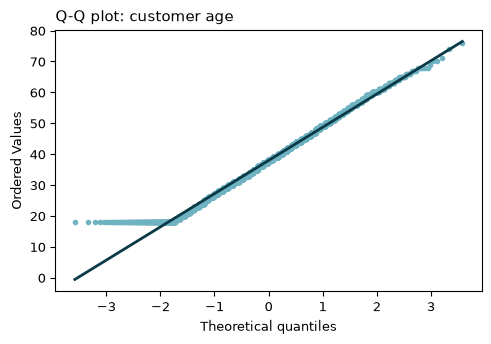

In [9]:
age = customers['age'].dropna()

fig, ax = plt.subplots()
stats.probplot(age, plot=ax)
ax.get_lines()[0].set(color='#6fb3c2', markersize=3)
ax.get_lines()[1].set_color('#0b3a47')
ax.set_title('Q-Q plot: customer age')
plt.show()

### `stats.shapiro()`

In [10]:
age_shapiro = stats.shapiro(age)
print(f'statistic: {age_shapiro.statistic}')
print(f'pvalue: {age_shapiro.pvalue}')

statistic: 0.9888561538493439
pvalue: 2.5068774406570742e-17


### `stats.normaltest()`

In [11]:
print(p_text(stats.normaltest(age).pvalue))

p < 0.001


### `stats.anderson()`

In [12]:
print(stats.anderson(age, method='interpolate').pvalue)

0.01


### Big samples flag tiny departures

In [13]:
for n in [30, 200, 1000, len(age)]:
    ages = age.sample(n, random_state=42)
    print(f'{n:>5} ages: {p_text(stats.shapiro(ages).pvalue)}')

   30 ages: p = 0.527
  200 ages: p = 0.016
 1000 ages: p < 0.001
 4043 ages: p < 0.001


## 13.4 One Group Against a Target

### `stats.ttest_1samp()`

In [14]:
delivery_test = stats.ttest_1samp(delivery, popmean=3)
print(f'statistic: {delivery_test.statistic}')
print(f'df: {delivery_test.df}')
print(f'pvalue: {delivery_test.pvalue}')

statistic: 32.02054533213076
df: 28771
pvalue: 4.312142789853693e-221


In [15]:
ci = delivery_test.confidence_interval()
late_hours = (delivery.mean() - 3) * 24
print(p_text(delivery_test.pvalue))
print(f'Average: {delivery.mean():.2f} days, '
      f'95% CI {ci.low:.2f} to {ci.high:.2f}')
print(f'About {late_hours:.0f} hours over the promise')

p < 0.001
Average: 3.30 days, 95% CI 3.28 to 3.32
About 7 hours over the promise


## 13.5 Paired Measurements

In [16]:
survey[['customer_id', 'house_blend_rating',
        'new_blend_rating']].head()

,customer_id,house_blend_rating,new_blend_rating
0,1262,6,7
1,1295,6,5
2,1413,6,5
3,1420,8,9
4,1506,6,5


In [17]:
blend_diff = survey['new_blend_rating'] - survey['house_blend_rating']
blend_diff.describe().round(2)

count    532.00
mean       0.43
std        1.33
min       -4.00
25%        0.00
50%        0.00
75%        1.00
max        4.00
dtype: float64

### `stats.ttest_rel()`

In [18]:
blend_test = stats.ttest_rel(survey['new_blend_rating'],
                             survey['house_blend_rating'])
blend_ci = blend_test.confidence_interval()
print(p_text(blend_test.pvalue))
print(f'New minus house: {blend_diff.mean():.2f} points, '
      f'95% CI {blend_ci.low:.2f} to {blend_ci.high:.2f}')

p < 0.001
New minus house: 0.43 points, 95% CI 0.31 to 0.54


### `stats.wilcoxon()`

In [19]:
print(p_text(stats.wilcoxon(survey['new_blend_rating'],
                            survey['house_blend_rating']).pvalue))
print(f'Preferred new: {(blend_diff > 0).sum()}, '
      f'preferred house: {(blend_diff < 0).sum()}, '
      f'same: {(blend_diff == 0).sum()}')

p < 0.001
Preferred new: 246, preferred house: 121, same: 165


## 13.6 Two Separate Groups

### `stats.ttest_ind()`

In [20]:
mobile = responses.loc[responses['device'] == 'Mobile',
                       'satisfaction']
desktop = responses.loc[responses['device'] == 'Desktop',
                        'satisfaction']
device_test = stats.ttest_ind(mobile, desktop, equal_var=False)
print(p_text(device_test.pvalue))

p = 0.568


### Welch's t-test with `equal_var=False`

In [21]:
student = stats.ttest_ind(mobile, desktop)
device_ci = device_test.confidence_interval()
print(f'Student: {p_text(student.pvalue)}')
print(f'Mobile minus desktop: {mobile.mean() - desktop.mean():.3f}, '
      f'95% CI {device_ci.low:.3f} to {device_ci.high:.3f}')

Student: p = 0.574
Mobile minus desktop: -0.041, 95% CI -0.184 to 0.101


## 13.7 When the Data Isn't Normal

In [22]:
add_ons = orders[orders['order_type'] == 'Add-on'].merge(
    customers[['customer_id', 'region']], on='customer_id',
    validate='many_to_one')
west = add_ons.loc[add_ons['region'] == 'West', 'amount']
south = add_ons.loc[add_ons['region'] == 'South', 'amount']
pd.DataFrame({'West': west.describe(),
              'South': south.describe()}).round(2)

,West,South
count,1335.00,1182.00
mean,27.88,25.39
std,24.07,39.29
min,6.80,4.61
25%,15.68,13.16
50%,21.83,18.19
75%,33.78,28.88
max,371.40,630.63


In [23]:
region_welch = stats.ttest_ind(west, south, equal_var=False)
print(p_text(region_welch.pvalue))

p = 0.060


### `stats.mannwhitneyu()`

In [24]:
region_mw = stats.mannwhitneyu(west, south)
print(p_text(region_mw.pvalue))

p < 0.001


In [25]:
share_bigger = region_mw.statistic / (len(west) * len(south))
print(f'A West add-on beats a South add-on {share_bigger:.0%} '
      'of the time')

A West add-on beats a South add-on 59% of the time


## 13.8 Testing Categories

In [26]:
customers['cancelled'] = customers['customer_id'].isin(
    cancellations['customer_id'])
plan_cancel = pd.crosstab(customers['plan'], customers['cancelled'])
plan_cancel

cancelled,False,True
plan,,
Basic,568,1319
Premium,509,303
Standard,764,747


### `stats.chi2_contingency()`

In [27]:
plan_test = stats.chi2_contingency(plan_cancel)
print(f'statistic: {plan_test.statistic}')
print(f'dof: {plan_test.dof}')
print(f'pvalue: {plan_test.pvalue}')

statistic: 289.6768769872333
dof: 2
pvalue: 1.2515995396561556e-63


In [28]:
expected = pd.DataFrame(plan_test.expected_freq,
                        index=plan_cancel.index,
                        columns=plan_cancel.columns)
expected.round(0)

cancelled,False,True
plan,,
Basic,825.0,1062.0
Premium,355.0,457.0
Standard,661.0,850.0


In [29]:
print(p_text(plan_test.pvalue))
print(f"Cramér's V: {stats.contingency.association(plan_cancel):.2f}")
print(customers.groupby('plan')['cancelled'].mean().round(3))

p < 0.001
Cramér's V: 0.26
plan
Basic       0.699
Premium     0.373
Standard    0.494
Name: cancelled, dtype: float64


## 13.9 Is This Correlation Real?

### `stats.pearsonr()` p-values

In [30]:
spend = orders.groupby('customer_id')['amount'].sum()
customers['total_spend'] = customers['customer_id'].map(spend)
with_age = customers.dropna(subset=['age'])
age_spend = stats.pearsonr(with_age['age'], with_age['total_spend'])
r_ci = age_spend.confidence_interval()
print(p_text(age_spend.pvalue))
print(f'r = {age_spend.statistic:.2f}, '
      f'95% CI {r_ci.low:.2f} to {r_ci.high:.2f}')

p < 0.001
r = 0.10, 95% CI 0.07 to 0.13


### `stats.spearmanr()` p-values

In [31]:
sat_rec = stats.spearmanr(responses['satisfaction'],
                          responses['recommend_score'])
survey_age = responses.dropna(subset=['age'])
sat_age = stats.spearmanr(survey_age['satisfaction'],
                          survey_age['age'])
print(f'Satisfaction vs recommend: rho = {sat_rec.statistic:.2f}, '
      f'{p_text(sat_rec.pvalue)}')
print(f'Satisfaction vs age: rho = {sat_age.statistic:.2f}, '
      f'{p_text(sat_age.pvalue)}')

Satisfaction vs recommend: rho = 0.70, p < 0.001


Satisfaction vs age: rho = 0.06, p = 0.187


## 13.10 Effect Size: Significant Isn't the Same as Important

In [32]:
order_city = orders.merge(customers[['customer_id', 'city']],
                          on='customer_id', validate='many_to_one')
chicago = order_city.loc[order_city['city'] == 'Chicago',
                         'delivery_days']
chicago_test = stats.ttest_1samp(chicago, popmean=3)
chicago_ci = chicago_test.confidence_interval()
print(f'{len(chicago):,} orders, average {chicago.mean():.2f} days, '
      f'{p_text(chicago_test.pvalue)}')
print(f'95% CI {chicago_ci.low:.2f} to {chicago_ci.high:.2f} days')
print(f'Gap: about {(chicago.mean() - 3) * 24:.0f} hours')

2,117 orders, average 3.08 days, p = 0.016
95% CI 3.01 to 3.14 days
Gap: about 2 hours


### Cohen's d

In [33]:
def cohens_d(a, b):
    pooled_var = (((len(a) - 1) * a.var() + (len(b) - 1) * b.var())
                  / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / np.sqrt(pooled_var)

print(f'Mobile vs desktop satisfaction: '
      f'd = {cohens_d(mobile, desktop):.2f}')
print(f'West vs South log add-on amount: '
      f'd = {cohens_d(np.log1p(west), np.log1p(south)):.2f}')

Mobile vs desktop satisfaction: d = -0.05
West vs South log add-on amount: d = 0.28


In [34]:
d_chicago = (chicago.mean() - 3) / chicago.std()
print(f'Chicago vs 3 days: d = {d_chicago:.2f}')

Chicago vs 3 days: d = 0.05
